<a href="https://colab.research.google.com/github/BilalKhanAI/Dubai-Real-Estate-Price-Prediction/blob/main/Dubai_Housing_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

print("Loading dataset sample...")
# Load 50,000 rows
df = pd.read_csv("dld_sales_transactions.csv", nrows=50000)

# Find target price column automatically
target = None
for col in df.columns:
  if "worth" in col.lower() or "price" in col.lower() or "amount" in col.lower():
    target = col
    break

if not target:
  target = df.columns[-1]

print(f"Using '{target}' as target price variable.")

# Clean data and keep ONLY numeric columns to save RAM
df = df.select_dtypes(include=[np.number])
df = df.dropna(subset=[target])
df = df[df[target] > 10000]

print("Data loaded, cleaned, and RAM-optimized successfully!")

Loading dataset sample...
Using 'price_aed' as target price variable.
Data loaded, cleaned, and RAM-optimized successfully!


Training model...

--- MODEL RESULTS ---
Mean Absolute Error (MAE): AED 212,208.48
Model Accuracy (R² Score): 89.47%


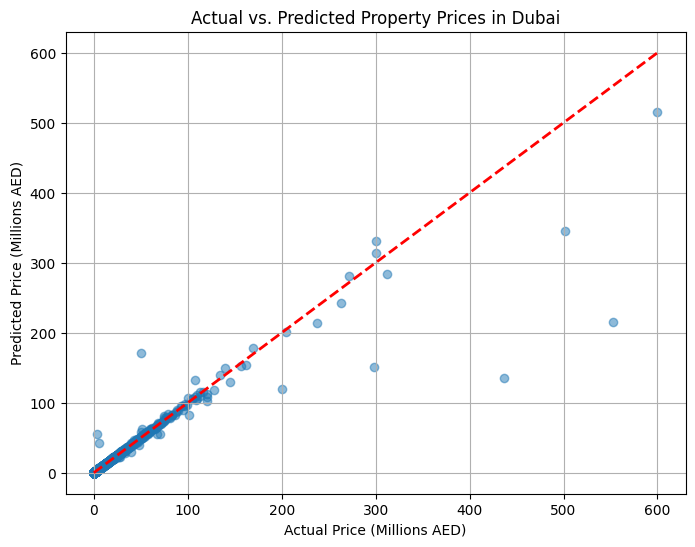


Graph generated and saved as 'actual_vs_predicted.png'!


In [2]:
# Separate features (X) and target (y)
X = df.drop(columns=[target])
y = df[target]

# 80/20 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train Model
print("Training model...")
model = RandomForestRegressor(n_estimators=50, random_state=42)
model.fit(X_train, y_train)

# Predictions & Metrics
predictions = model.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print(f"\n--- MODEL RESULTS ---")
print(f"Mean Absolute Error (MAE): AED {mae:,.2f}")
print(f"Model Accuracy (R² Score): {r2 * 100:.2f}%")

# Generate and Save Graph
plt.figure(figsize=(8, 6))
plt.scatter(y_test / 1e6, predictions / 1e6, alpha=0.5, color="#1f77b4")
plt.plot(
    [y_test.min() / 1e6, y_test.max() / 1e6],
    [y_test.min() / 1e6, y_test.max() / 1e6],
    "r--",
    lw=2,
)
plt.xlabel("Actual Price (Millions AED)")
plt.ylabel("Predicted Price (Millions AED)")
plt.title("Actual vs. Predicted Property Prices in Dubai")
plt.grid(True)

plt.savefig("actual_vs_predicted.png", dpi=300)
plt.show()
print("\nGraph generated and saved as 'actual_vs_predicted.png'!")